# Phase 2: Tumour segmentation (evangeline, patient 29)

The tumour is searched **inside the liver** (the liver mask is the region of interest; in the group app it comes from the liver members' segmentation).

| | This member's algorithms |
|---|---|
| Morphology | custom **ellipse 5x5** and hand-made **ring 9x9** structuring elements |
| Method A | **adaptive local thresholding** (darker than the local mean) + morphology |
| Method B | **marker-controlled watershed** |
| Validation | Dice + IoU against the ground-truth tumour |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

from scipy import ndimage as ndi
from skimage.filters import threshold_local, sobel
from skimage.segmentation import watershed
from skimage.measure import label, regionprops

NAME = "evangeline"
ENH = "../phase1/outputs_evangeline/enhanced"
GT = f"../data/slices/{NAME}"
OUT = "outputs_evangeline"
FIGS = "../report/figures/evangeline"
FAILED = "../report/failed_cases/evangeline"
for d in [f"{OUT}/adaptive", f"{OUT}/watershed", FIGS, FAILED]:
    os.makedirs(d, exist_ok=True)

files = sorted(glob.glob(f"{ENH}/*_enh.png"))
print(len(files), "enhanced slices found")

def load(p):
    sid = os.path.basename(p).replace("_enh.png", "")
    return (sid, cv2.imread(p, 0), cv2.imread(f"{GT}/{sid}_liver.png", 0) > 0,
            cv2.imread(f"{GT}/{sid}_tumour.png", 0) > 0)

def dice(pred, gt):
    """Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none."""
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-9)

def iou(pred, gt):
    """Jaccard / IoU = |A n B| / |A u B|."""
    return (pred & gt).sum() / ((pred | gt).sum() + 1e-9)

def overlay(img, pred, gt):
    """RED = predicted outline, GREEN = ground-truth outline."""
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for mask, colour in [(gt, (0, 255, 0)), (pred, (255, 0, 0))]:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, colour, 2)
    return rgb

example = max(files, key=lambda f: load(f)[3].sum())
sid, img, liver, gt = load(example)
ys, xs = np.where(liver)
r0, r1, c0, c1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
print("example slice:", sid)

22 enhanced slices found


example slice: p29_s69


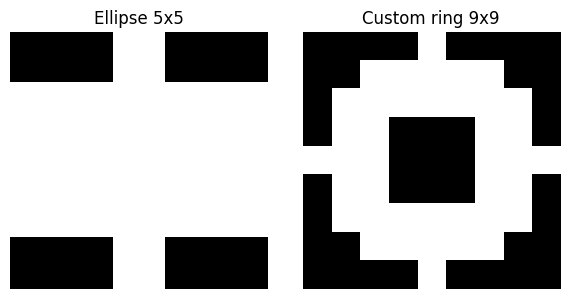

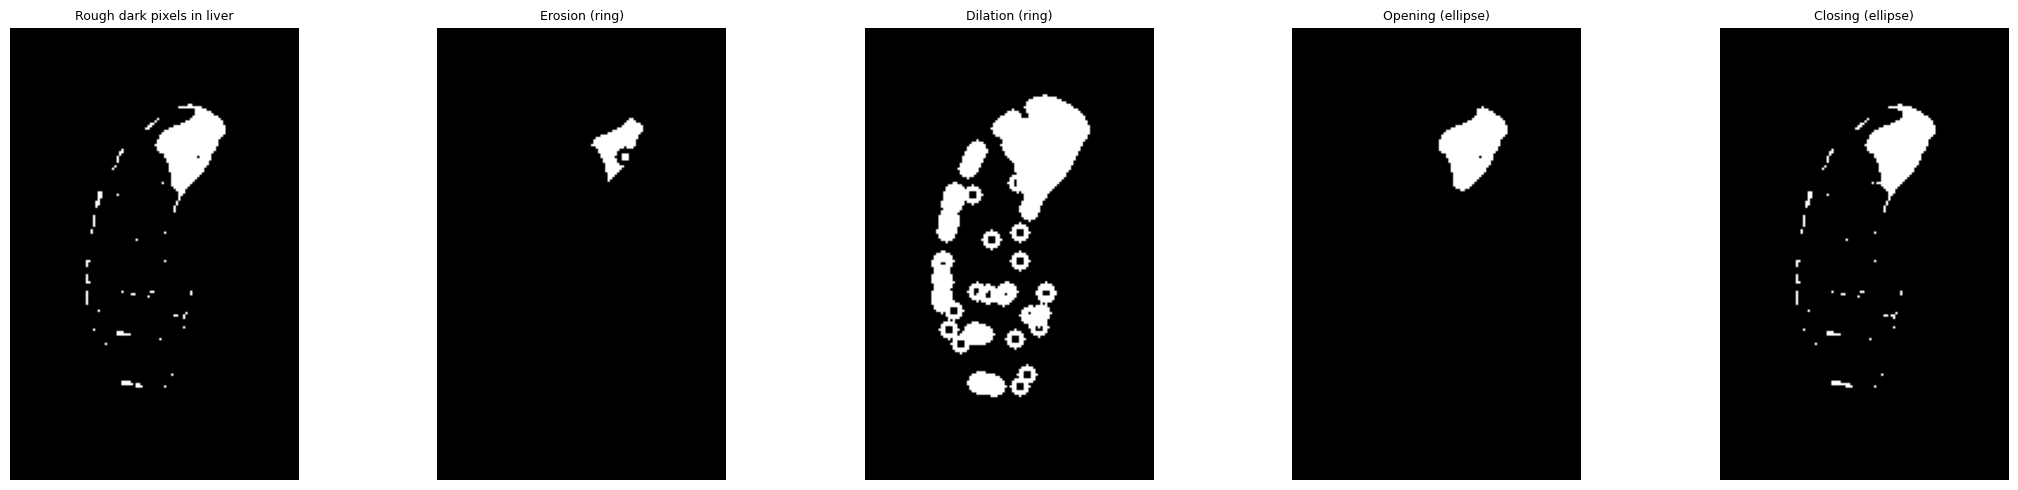

In [2]:
SE_ELLIPSE_5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
yy, xx = np.mgrid[-4:5, -4:5]
SE_RING_9 = ((yy ** 2 + xx ** 2 <= 16) & (yy ** 2 + xx ** 2 >= 4)).astype(np.uint8)   # hand-made ring (hollow disc)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, se, t in zip(ax, [SE_ELLIPSE_5, SE_RING_9], ["Ellipse 5x5", "Custom ring 9x9"]):
    a.imshow(se, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

def liver_roi(liver):
    return cv2.erode(liver.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0

def clean(mask, min_area=30):
    """Opening removes specks, small blobs are dropped, closing + hole filling smooth the result."""
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, SE_ELLIPSE_5) > 0
    lab = label(mask); out = np.zeros(mask.shape, bool)
    for r in regionprops(lab):
        if r.area >= min_area:
            out[lab == r.label] = True
    return ndi.binary_fill_holes(cv2.morphologyEx(out.astype(np.uint8), cv2.MORPH_CLOSE, SE_ELLIPSE_5) > 0)

roi = liver_roi(liver)
rough = ((img < np.median(img[roi]) - 20) & roi).astype(np.uint8)
ops = {"Rough dark pixels in liver": rough, "Erosion (ring)": cv2.erode(rough, SE_RING_9),
       "Dilation (ring)": cv2.dilate(rough, SE_RING_9), "Opening (ellipse)": cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_ELLIPSE_5),
       "Closing (ellipse)": cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_ELLIPSE_5)}
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, (t, m) in zip(ax, ops.items()):
    a.imshow(m[r0:r1, c0:c1], cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_morphology.png", dpi=120); plt.show()

**Method A: adaptive local thresholding.** Each liver pixel is compared with the mean of the 151x151 window around it; it is marked as tumour if it is more than 8 grey levels **darker** than that local mean. Pixels outside the liver are first set to the liver's median, so the dark background does not pull the local mean down near the liver edge.

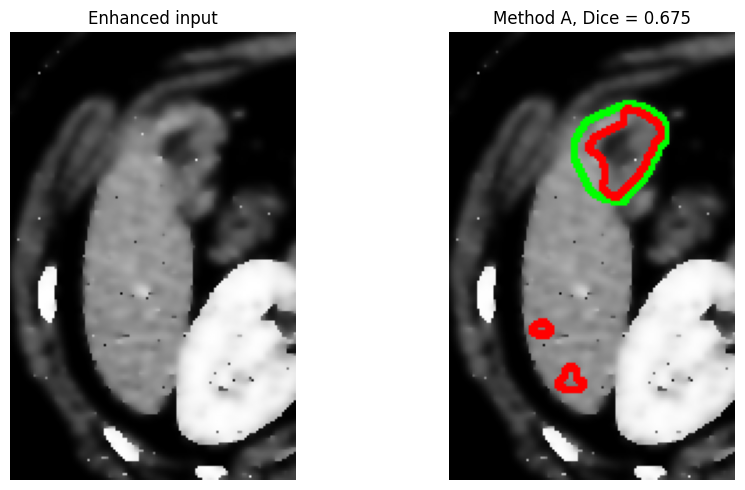

In [3]:
BLOCK, C = 151, 8

def segment_adaptive(img, liver):
    roi = liver_roi(liver)
    if roi.sum() < 50:
        return np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0).astype(float)
    filled = smooth.copy(); filled[~roi] = np.median(smooth[roi])
    local_mean = threshold_local(filled, block_size=BLOCK, method="mean")
    return clean((smooth < local_mean - C) & roi)

pred_a = segment_adaptive(img, liver)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray"); ax[0].set_title("Enhanced input")
ax[1].imshow(overlay(img, pred_a, gt)[r0:r1, c0:c1]); ax[1].set_title(f"Method A, Dice = {dice(pred_a, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_a_adaptive.png", dpi=120); plt.show()

**Method B: marker-controlled watershed.** Markers: **tumour** = pixels clearly darker than the liver (median - 0.75 x std, after opening); **background** = everything outside the liver + liver pixels brighter than the median. Watershed floods the edge (Sobel gradient) image from both markers; the tumour boundary is where the floods meet.

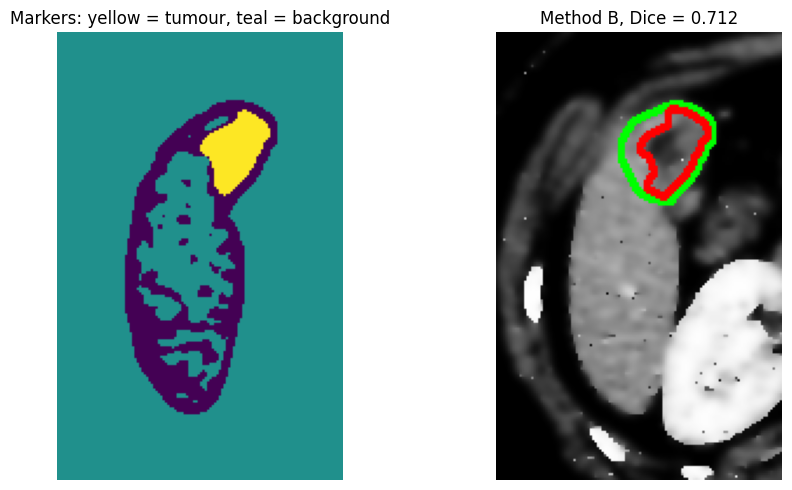

In [4]:
K = 0.75

def segment_watershed(img, liver, return_markers=False):
    roi = liver_roi(liver)
    markers = np.zeros(img.shape, np.int32)
    if roi.sum() < 50:
        return (np.zeros(img.shape, bool), markers) if return_markers else np.zeros(img.shape, bool)
    smooth = cv2.GaussianBlur(img, (5, 5), 0)
    med, sd = np.median(smooth[roi]), smooth[roi].std()
    markers[~cv2.dilate(liver.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)] = 1   # outside liver
    markers[(smooth > med) & roi] = 1                                                          # normal liver
    core = cv2.morphologyEx(((smooth < med - K * sd) & roi).astype(np.uint8), cv2.MORPH_OPEN, SE_ELLIPSE_5) > 0
    markers[core] = 2                                                                          # sure tumour
    labels = watershed(sobel(smooth / 255.0), markers)
    mask = clean((labels == 2) & roi)
    return (mask, markers) if return_markers else mask

pred_b, markers = segment_watershed(img, liver, return_markers=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(markers[r0:r1, c0:c1], cmap="viridis"); ax[0].set_title("Markers: yellow = tumour, teal = background")
ax[1].imshow(overlay(img, pred_b, gt)[r0:r1, c0:c1]); ax[1].set_title(f"Method B, Dice = {dice(pred_b, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_b_watershed.png", dpi=120); plt.show()

In [5]:
rows = []
for f in files:
    sid, img, liver, gt = load(f)
    for method, fn in [("adaptive", segment_adaptive), ("watershed", segment_watershed)]:
        pred = fn(img, liver)
        cv2.imwrite(f"{OUT}/{method}/{sid}_tumour_pred.png", pred.astype(np.uint8) * 255)
        rows.append({"slice": sid, "method": method, "Dice": dice(pred, gt), "IoU": iou(pred, gt), "GT tumour pixels": int(gt.sum())})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase2_metrics.csv", index=False)
print(results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"]).round(3))
print("\nPer slice Dice:")
print(results.pivot(index="slice", columns="method", values="Dice").round(3))

            Dice                IoU            
            mean    std  min   mean    std  min
method                                         
adaptive   0.585  0.241  0.0  0.448  0.211  0.0
watershed  0.600  0.270  0.0  0.472  0.241  0.0

Per slice Dice:
method   adaptive  watershed
slice                       
p29_s56     0.000      0.000
p29_s57     0.298      0.288
p29_s58     0.466      0.468
p29_s59     0.556      0.544
p29_s60     0.743      0.749
p29_s61     0.686      0.694
p29_s62     0.695      0.690
p29_s63     0.711      0.825
p29_s64     0.789      0.844
p29_s65     0.742      0.731
p29_s66     0.838      0.831
p29_s67     0.837      0.822
p29_s68     0.707      0.794
p29_s69     0.675      0.712
p29_s70     0.747      0.755
p29_s71     0.686      0.791
p29_s72     0.700      0.820
p29_s73     0.731      0.744
p29_s74     0.557      0.607
p29_s75     0.433      0.308
p29_s76     0.213      0.139
p29_s77     0.070      0.044


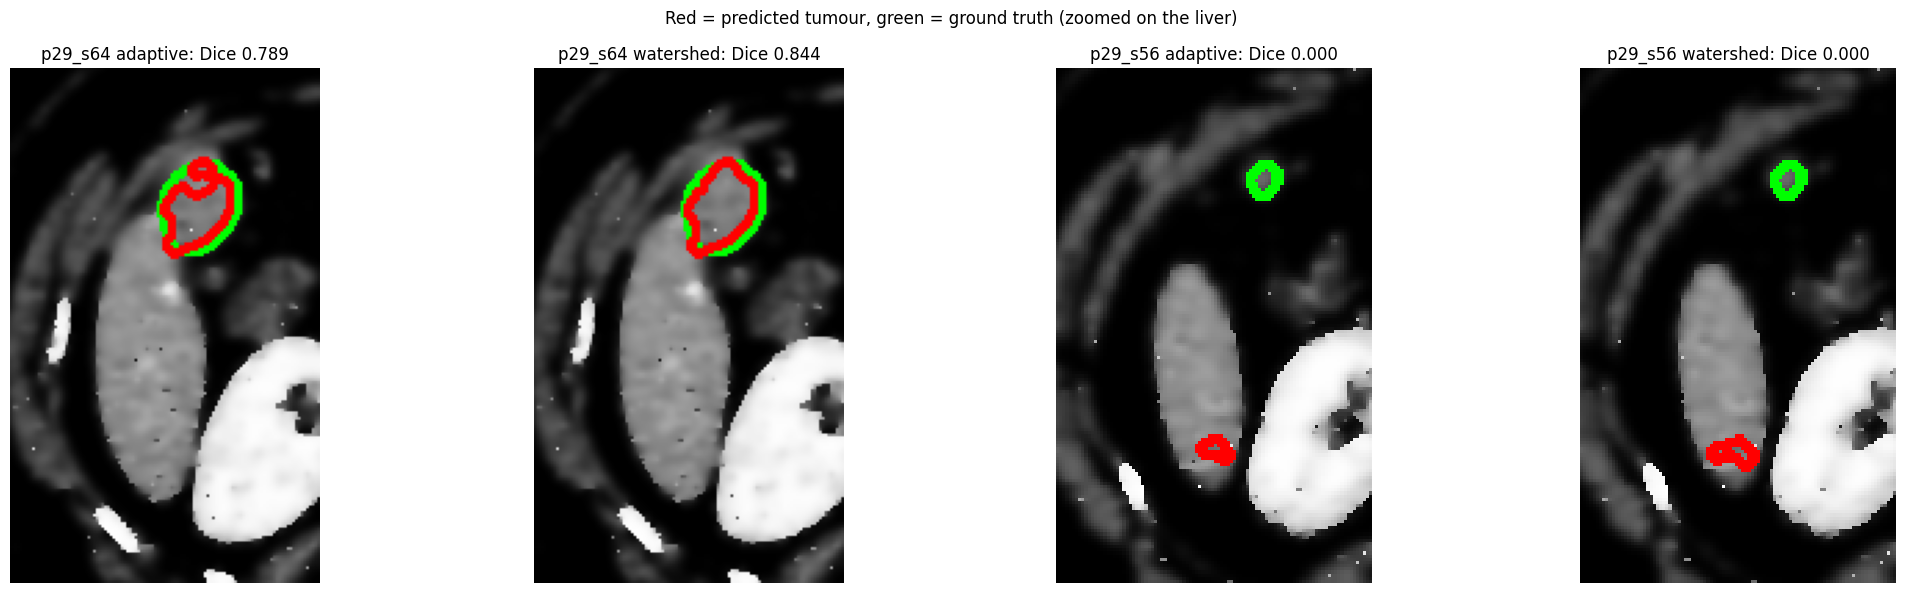

In [6]:
best_method = results.groupby("method")["Dice"].mean().idxmax()
d = results[results.method == best_method].set_index("slice")["Dice"]
best_sid, worst_sid = d.idxmax(), d.idxmin()
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (s, method) in zip(ax, [(best_sid, "adaptive"), (best_sid, "watershed"), (worst_sid, "adaptive"), (worst_sid, "watershed")]):
    _, img, liver, gt = load(f"{ENH}/{s}_enh.png")
    pred = cv2.imread(f"{OUT}/{method}/{s}_tumour_pred.png", 0) > 0
    ys, xs = np.where(liver)
    y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
    a.imshow(overlay(img, pred, gt)[y0:y1, x0:x1]); a.axis("off"); a.set_title(f"{s} {method}: Dice {dice(pred, gt):.3f}")
plt.suptitle("Red = predicted tumour, green = ground truth (zoomed on the liver)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_overlays.png", dpi=120); plt.show()

In [7]:
# ---- failed cases: every slice where the best method scored Dice < 0.7, with the likely reason ----
def failure_reason(pred, gt):
    if pred.sum() == 0:
        return "missed completely: nothing was segmented"
    if gt.sum() < 300:
        return f"very small tumour on this slice ({int(gt.sum())} pixels), near the top or bottom of the organ"
    if pred.sum() > 1.5 * gt.sum():
        return "over-segmentation: the mask leaked into neighbouring tissue"
    if pred.sum() < 0.6 * gt.sum():
        return "under-segmentation: only part of the tumour was found"
    return "boundary mismatch: right place, but the outline differs from the ground truth"

best_method = results.groupby("method")["Dice"].mean().idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]
lines = [f"# Phase 2 failed cases: {NAME} (tumour segmentation)", "",
         f"Best method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.", "",
         "| Slice | Dice ({}) | Ground-truth pixels | Predicted pixels | Likely reason |".format(best_method),
         "|---|---|---|---|---|"]
for _, row in failed.iterrows():
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_tumour_pred.png", 0) > 0
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt.sum())} | {int(pred.sum())} | {failure_reason(pred, gt)} |")
for _, row in failed.head(3).iterrows():                       # save overlays of the 3 worst
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_tumour_pred.png", 0) > 0
    cv2.imwrite(f"{FAILED}/{NAME}_{row.slice}_{best_method}_overlay.png", cv2.cvtColor(overlay(img, pred, gt), cv2.COLOR_RGB2BGR))
if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines += ["", "Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth)."]
open(f"{FAILED}/{NAME}_phase2_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Phase 2 failed cases: evangeline (tumour segmentation)

Best method: **watershed** (mean Dice 0.600). Slices with Dice < 0.7: 10 of 22.

| Slice | Dice (watershed) | Ground-truth pixels | Predicted pixels | Likely reason |
|---|---|---|---|---|
| p29_s56 | 0.000 | 75 | 85 | very small tumour on this slice (75 pixels), near the top or bottom of the organ |
| p29_s77 | 0.044 | 80 | 1383 | very small tumour on this slice (80 pixels), near the top or bottom of the organ |
| p29_s76 | 0.139 | 172 | 1237 | very small tumour on this slice (172 pixels), near the top or bottom of the organ |
| p29_s57 | 0.288 | 178 | 266 | very small tumour on this slice (178 pixels), near the top or bottom of the organ |
| p29_s75 | 0.308 | 363 | 1252 | over-segmentation: the mask leaked into neighbouring tissue |
| p29_s58 | 0.468 | 261 | 337 | very small tumour on this slice (261 pixels), near the top or bottom of the organ |
| p29_s59 | 0.544 | 429 | 432 | boundary mismatch: right place, but the outline d